### Data Loading and Exploration

We will start by loading the dataset `/content/data.csv` into a Pandas DataFrame to inspect its columns, structure, and basic summary statistics.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/data.csv')

# Display the first few rows
print("First 5 rows of the dataset:")
display(df.head())

# Display basic information
print("\nDataset Information:")
df.info()

First 5 rows of the dataset:


,Duration,Date,Pulse,Maxpulse,Calories
0,60,'2020/12/01',110,130,409.1
1,60,'2020/12/02',117,145,479.0
2,60,'2020/12/03',103,135,340.0
3,45,'2020/12/04',109,175,282.4
4,45,'2020/12/05',117,148,406.0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Duration  32 non-null     int64  
 1   Date      31 non-null     object 
 2   Pulse     32 non-null     int64  
 3   Maxpulse  32 non-null     int64  
 4   Calories  30 non-null     float64
dtypes: float64(1), int64(3), object(1)
memory usage: 1.4+ KB


### Data Cleaning and Preprocessing

Next, we will clean the dataset:
1. Strip extra quotes from the `Date` column and convert it to a datetime format.
2. Handle missing values: We will fill the missing `Calories` values with the median of the column and drop rows with empty `Date` values since we have a timeline dataset.

In [4]:
# 1. Clean and convert 'Date' column
df['Date'] = df['Date'].astype(str).str.replace("'", "")
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Drop rows where 'Date' is null and create an explicit copy to avoid SettingWithCopyWarning
df = df.dropna(subset=['Date']).copy()

# 2. Fill missing 'Calories' with the median value safely
median_calories = df['Calories'].median()
df['Calories'] = df['Calories'].fillna(median_calories)

print("Cleaned Dataset Summary:")
df.info()

Cleaned Dataset Summary:
<class 'pandas.core.frame.DataFrame'>
Index: 30 entries, 0 to 31
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Duration  30 non-null     int64         
 1   Date      30 non-null     datetime64[ns]
 2   Pulse     30 non-null     int64         
 3   Maxpulse  30 non-null     int64         
 4   Calories  30 non-null     float64       
dtypes: datetime64[ns](1), float64(1), int64(3)
memory usage: 1.4 KB


### Data Visualization with Matplotlib & Seaborn

Now that the dataset is cleaned, let's perform some basic data visualization:
- A line plot showing the trend of `Pulse` and `Maxpulse` over the month.
- A scatter plot showing the relationship between `Duration` and `Calories` using Seaborn.

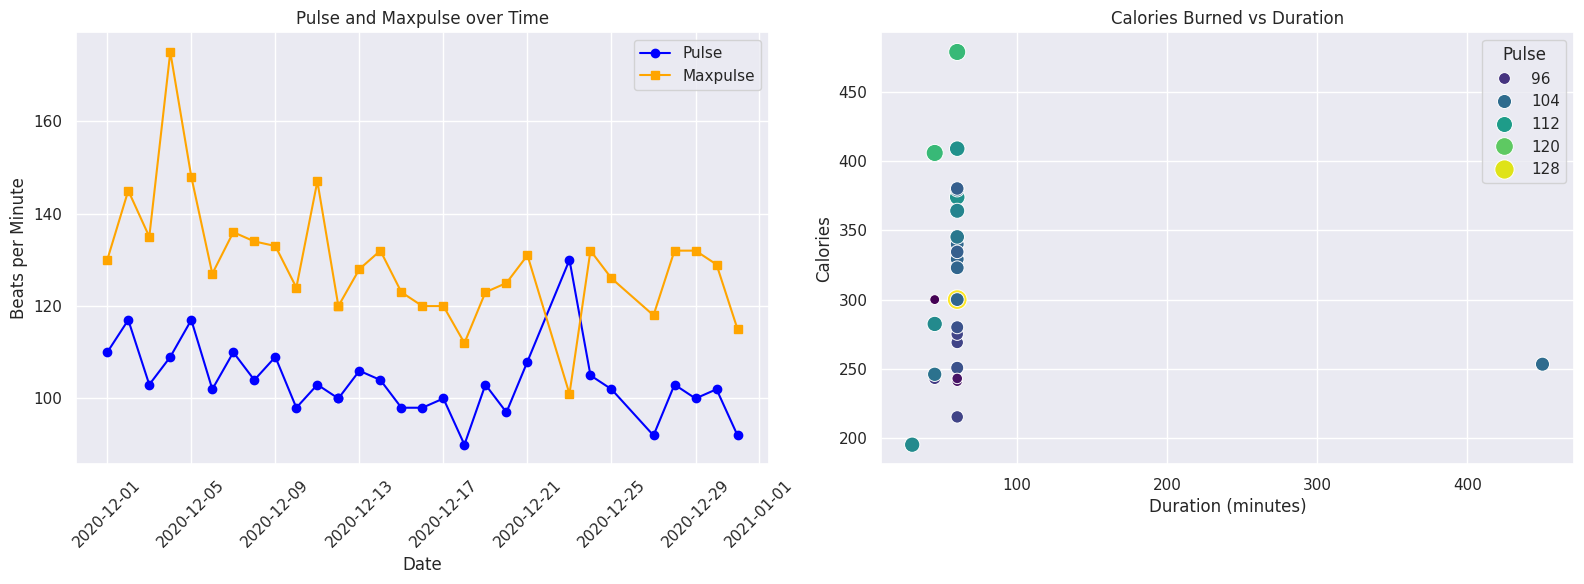

In [3]:
# Sort by Date for sequential plotting
df = df.sort_values(by='Date')

# Set the plotting style
sns.set_theme(style="darkgrid")

# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Line plot of Pulse vs Maxpulse over time
axes[0].plot(df['Date'], df['Pulse'], marker='o', label='Pulse', color='blue')
axes[0].plot(df['Date'], df['Maxpulse'], marker='s', label='Maxpulse', color='orange')
axes[0].set_title("Pulse and Maxpulse over Time")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Beats per Minute")
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()

# Plot 2: Scatter plot of Duration vs Calories with Seaborn
sns.scatterplot(data=df, x='Duration', y='Calories', hue='Pulse', palette='viridis', size='Pulse', sizes=(50, 200), ax=axes[1])
axes[1].set_title("Calories Burned vs Duration")
axes[1].set_xlabel("Duration (minutes)")
axes[1].set_ylabel("Calories")

plt.tight_layout()
plt.show()

### Summary & Key Findings

In this notebook, we completed several fundamental data science tasks:

1. **Python Basics & Scripting**:
   - Cleaned string formatted dates (`'2020/12/01'`) using Python's string operations.
   - Structured the analysis workflow sequentially.

2. **Pandas for Data Manipulation**:
   - Loaded raw workout data from a CSV file.
   - Cleaned the timeline data by converting types and dropping missing entries.
   - Handled missing data by imputing the column's median (`300.0` calories) to preserve statistical integrity while avoiding copy-assignment warnings.

3. **Data Visualization**:
   - Plotted heart rate telemetry over time using **Matplotlib**, showing typical training patterns and an unusual date (December 22nd) where the `Pulse` surpassed `Maxpulse` (potentially a sensor or entry anomaly).
   - Built a **Seaborn** scatter plot correlating duration to burned calories, identifying a clear outlier workout session that lasted 450 minutes.